In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_test = pd.read_csv("Hospital/test_data.csv")
data_train = pd.read_csv("Hospital/train_data.csv")
data_sample = pd.read_csv("Hospital/train_data.csv")

In [10]:
data_train

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911.0,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954.0,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745.0,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272.0,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558.0,41-50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,318434,6,a,6,X,3,radiotherapy,Q,F,4.0,86499,23.0,Emergency,Moderate,3,41-50,4144.0,11-20
318434,318435,24,a,1,X,2,anesthesia,Q,E,4.0,325,8.0,Urgent,Moderate,4,81-90,6699.0,31-40
318435,318436,7,a,4,X,3,gynecology,R,F,4.0,125235,10.0,Emergency,Minor,3,71-80,4235.0,11-20
318436,318437,11,b,2,Y,3,anesthesia,Q,D,3.0,91081,8.0,Trauma,Minor,5,11-20,3761.0,11-20


## Informació Dataset

### Información de dataset
- **case_id** : número de caso 
- **Hospital_code** : código único para el hospital ([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32])
- **Hospital_type_code:** código único para el tipo de Hospital (['a', 'b', 'c', 'd', 'e', 'f', 'g'], dtype=object)
- **City_Code_Hospital:** código de la Ciudad del Hospital ([ 1,  2,  3,  4,  5,  6,  7,  9, 10, 11, 13])
- **Hospital_region_code:** código de Región del Hospital (['X', 'Y', 'Z'], dtype=object)
- **Available Extra Rooms in Hospital:** número de habitaciones adicionales disponibles en el Hospital ([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 20, 21, 24])
- **Department:** departamento que supervisa el caso (['TB & Chest disease', 'anesthesia', 'gynecology', 'radiotherapy','surgery'], dtype=object)
- **Ward_Type:** código para el tipo de planta (['P', 'Q', 'R', 'S', 'T', 'U'], dtype=object)
- **Ward_Facility_Code:** código para la Instalación de la Sala (['A', 'B', 'C', 'D', 'E', 'F'], dtype=object)
- **Bed Grade:** estado de la cama en la sala ([ 1.,  2.,  3.,  4., nan])
- **patientid:** identificación única del paciente
- **City_Code_Patient:** código de ciudad para la paciente ([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,14., 15., 16., 18., 19., 20., 21., 22., 23., 24., 25., 26., 27.,28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38., nan])
- **Type of Admission:** tipo de Admisión registrado por el Hospital (['Emergency', 'Trauma', 'Urgent'], dtype=object)
- **Severity of Illness:** gravedad de la enfermedad registrada al momento del ingreso (['Extreme', 'Minor', 'Moderate'], dtype=object)
- **Visitors with Patient:** número de acompañantes con el paciente ([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 30, 32])
- **Age:** edad (['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70','71-80', '81-90', '91-100'], dtype=object)
- **Admission_Deposit:** depósito en el momento de la admisión (min [1800.0], max[11008.0])
- **Stay:** días de estancia hospitalaria por la paciente (['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70','71-80', '81-90', '91-100', 'More than 100 Days'], dtype=object)

# INFORMACIÓN IMPORTANTE SOBRE LA TABLA

In [28]:
data_train['Hospital_type_code'].value_counts().unique()

array([143425,  68946,  45928,  24770,  20389,  10703,   4277])

In [29]:
data_train['Hospital_type_code'].sort_values().unique()

array(['a', 'b', 'c', 'd', 'e', 'f', 'g'], dtype=object)

## Formato de las columnas

In [18]:
data_train.head()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911.0,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954.0,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745.0,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272.0,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558.0,41-50


In [13]:
data_train.info() #Ver en que formato está cada columna de la tabla train.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available Extra Rooms in Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed Grade                          318325 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3139

In [19]:
data_train['Stay'].value_counts()

Stay
21-30                 87491
11-20                 78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64

In [20]:
data_train['Stay'].value_counts(normalize = True).sort_index()

Stay
0-10                  0.074124
11-20                 0.245382
21-30                 0.274751
31-40                 0.173217
41-50                 0.036877
51-60                 0.109968
61-70                 0.008617
71-80                 0.032201
81-90                 0.015193
91-100                0.008683
More than 100 Days    0.020987
Name: proportion, dtype: float64

# Nulos de la tabla

In [14]:
data_train.isnull().sum() #Ver cuantos nulos hay en la tabla train.

case_id                                 0
Hospital_code                           0
Hospital_type_code                      0
City_Code_Hospital                      0
Hospital_region_code                    0
Available Extra Rooms in Hospital       0
Department                              0
Ward_Type                               0
Ward_Facility_Code                      0
Bed Grade                             113
patientid                               0
City_Code_Patient                    4532
Type of Admission                       0
Severity of Illness                     0
Visitors with Patient                   0
Age                                     0
Admission_Deposit                       0
Stay                                    0
dtype: int64

In [3]:
(data_train.isnull().sum() /data_train.shape[0] * 100).round(2)

case_id                              0.00
Hospital_code                        0.00
Hospital_type_code                   0.00
City_Code_Hospital                   0.00
Hospital_region_code                 0.00
Available Extra Rooms in Hospital    0.00
Department                           0.00
Ward_Type                            0.00
Ward_Facility_Code                   0.00
Bed Grade                            0.04
patientid                            0.00
City_Code_Patient                    1.42
Type of Admission                    0.00
Severity of Illness                  0.00
Visitors with Patient                0.00
Age                                  0.00
Admission_Deposit                    0.00
Stay                                 0.00
dtype: float64

### Ordenamos las variables categóricas para graficar

In [49]:
#Ordenamos la variable stay (dias de estancia) de menor a mayor.
stay_order = [
    '0-10',
    '11-20',
    '21-30',
    '31-40',
    '41-50',
    '51-60',
    '61-70',
    '71-80',
    '81-90',
    '91-100',
    'More than 100 Days'
]

data_train['Stay'] = pd.Categorical(data_train['Stay'], categories = stay_order, ordered = True)

In [34]:
#Ordenamos la variable age (edad) de menor a mayor.
age_order = sorted(data_train['Age'].unique(), 
            key=lambda x: int(x.split('-')[0]))

data_train['Age'] = pd.Categorical(data_train['Age'], categories= age_order, ordered = True)

In [42]:
data_train.duplicated().sum()

np.int64(0)

## Relaciones 

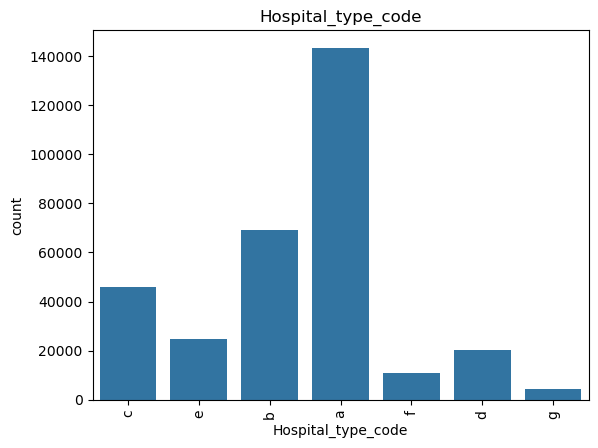

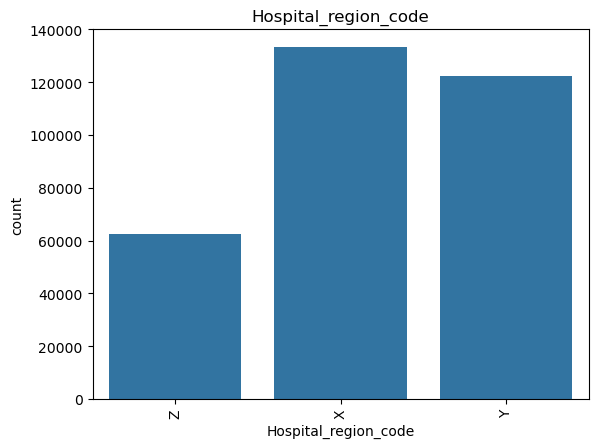

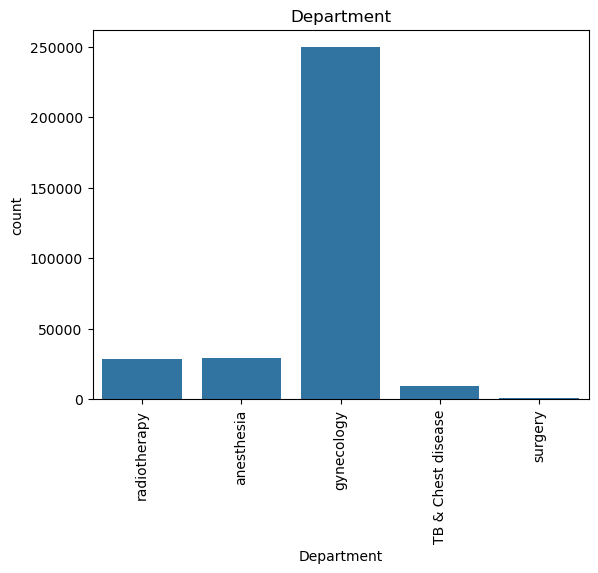

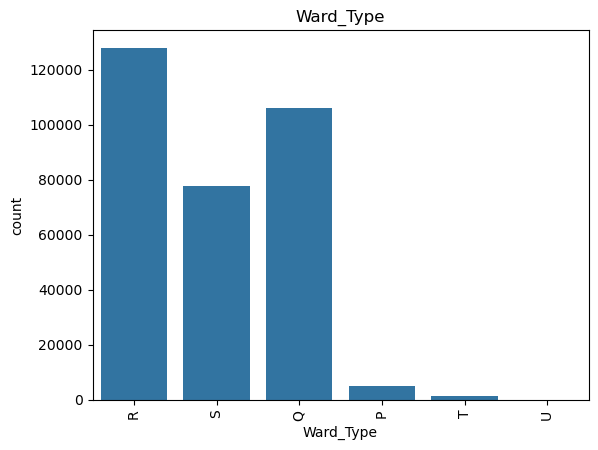

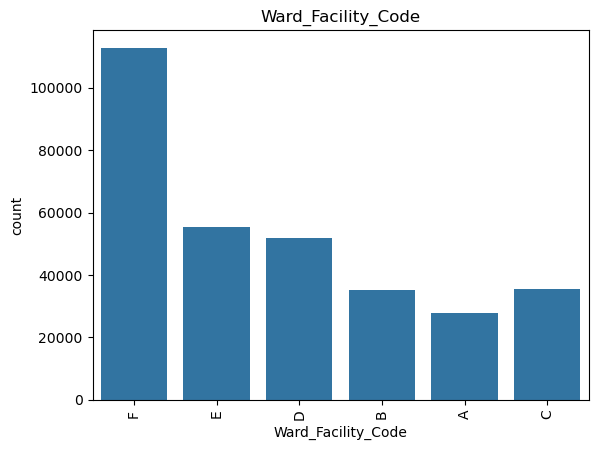

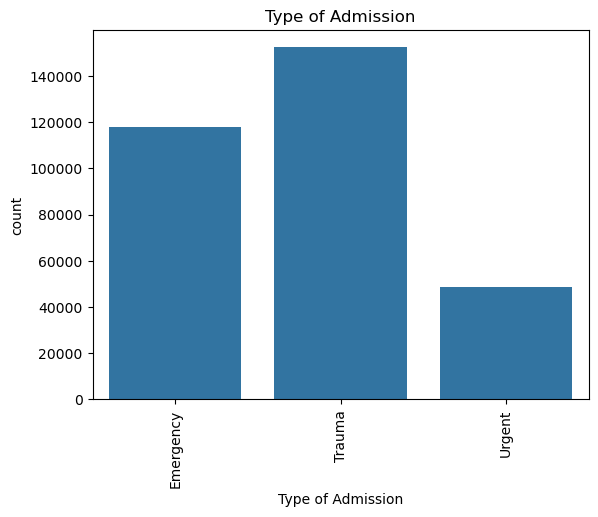

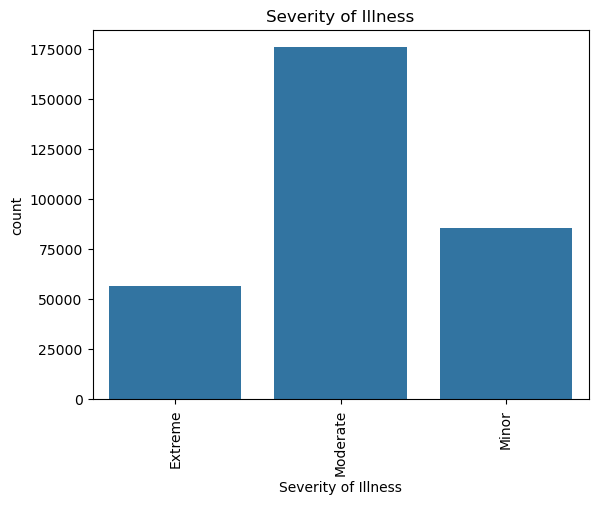

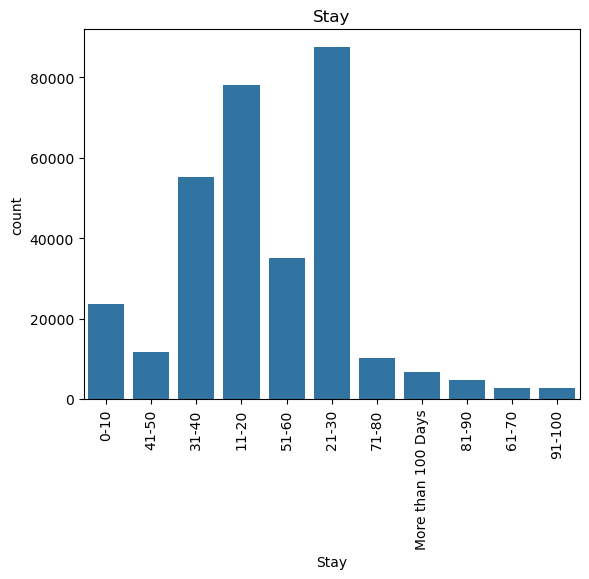

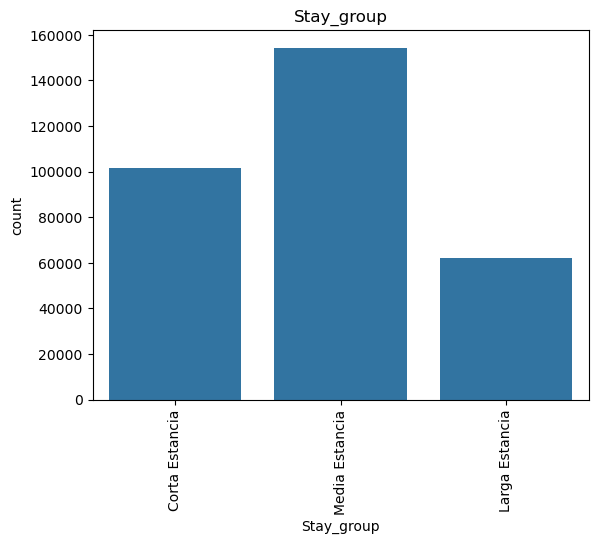

In [35]:
filtro = data_train.dtypes == "object"

for columna in data_train.columns[filtro]:
    sns.countplot(data = data_train, x = columna)
    plt.title(columna)
    plt.xticks(rotation = 90)
    plt.show()

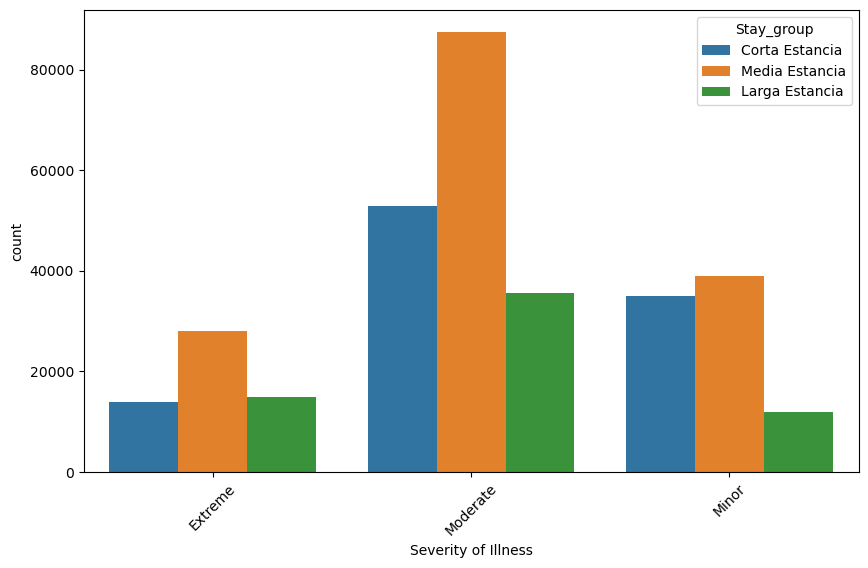

In [36]:
plt.figure(figsize=(10,6))
sns.countplot(
    data = data_train, 
    x = "Severity of Illness", 
    hue = "Stay_group")
plt.xticks(rotation=45)
plt.show()

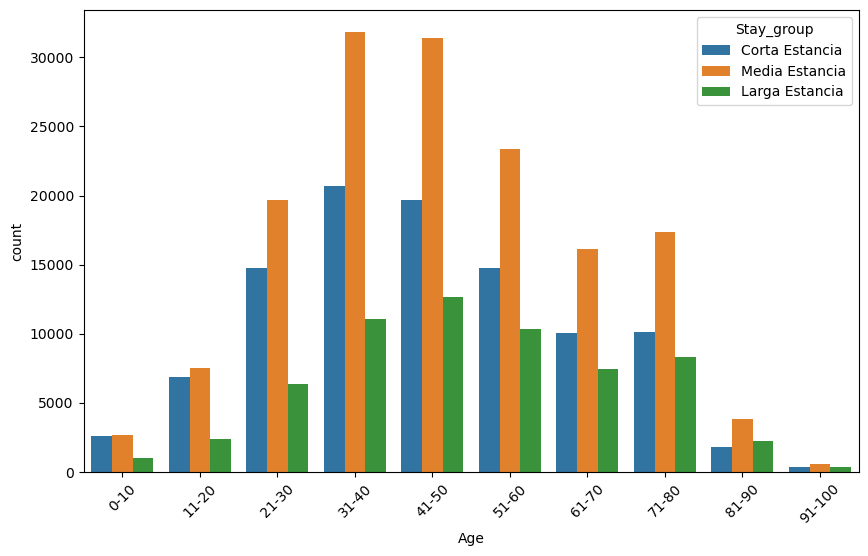

In [37]:
plt.figure(figsize=(10,6))
sns.countplot(
    data = data_train, 
    x = "Age", 
    hue = "Stay_group")
plt.xticks(rotation=45)
plt.show()

In [ ]:
plt.figure(figsize = (10,6))
sns.countplot(
    data = data_train, 
    x = "Admission_", 
    hue = "Stay_group")
plt.xticks(rotation=45)
plt.show()

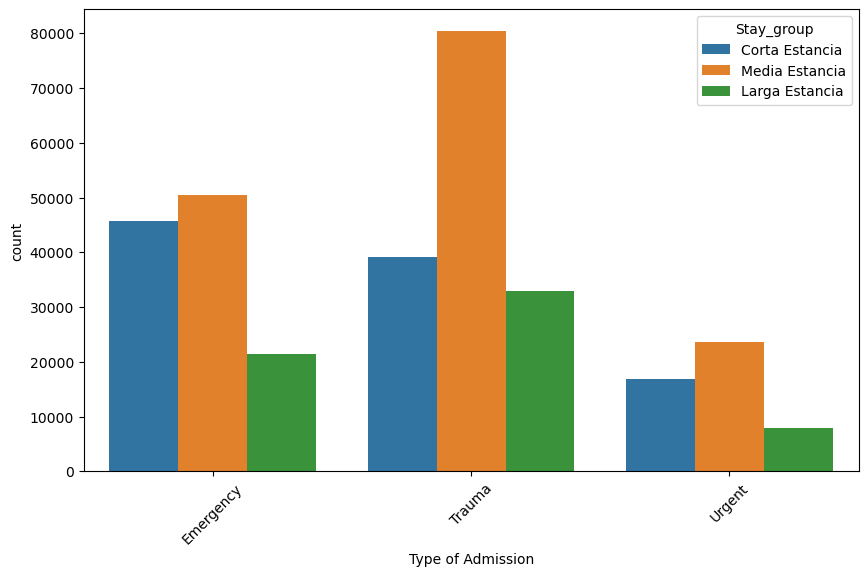

In [38]:
plt.figure(figsize = (10,6))
sns.countplot(
    data = data_train, 
    x = "", 
    hue = "Stay_group")
plt.xticks(rotation=45)
plt.show()

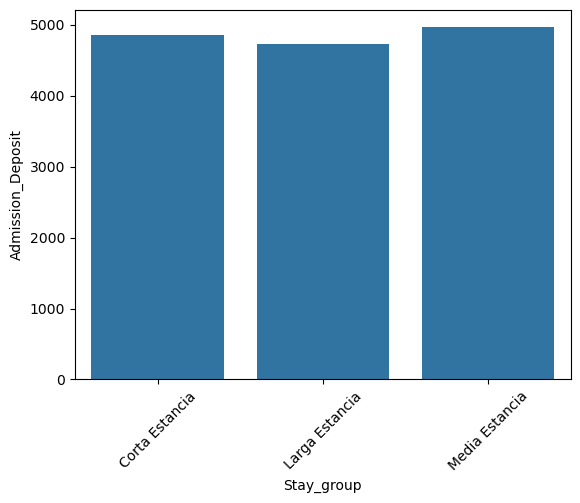

In [48]:

sns.barplot(
    data = mean_deposit, 
    x = "Stay_group", 
    y = "Admission_Deposit")
plt.xticks(rotation=45)
plt.show()

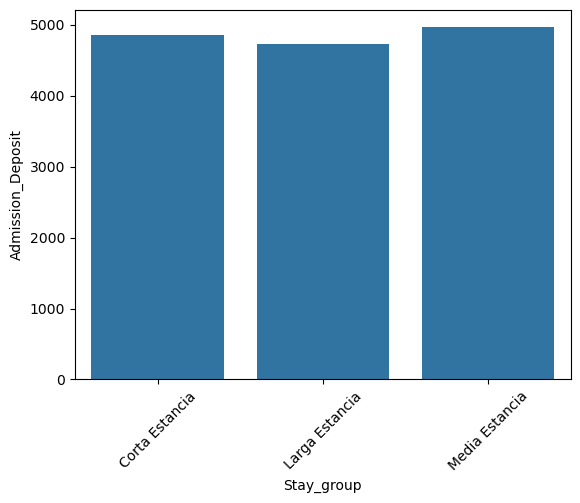

In [41]:
mean_deposit = data_train.groupby("Stay_group")["Admission_Deposit"].mean().reset_index()

sns.barplot(
    data = mean_deposit, 
    x = "Stay_group", 
    y = "Admission_Deposit")
plt.xticks(rotation=45)
plt.show()

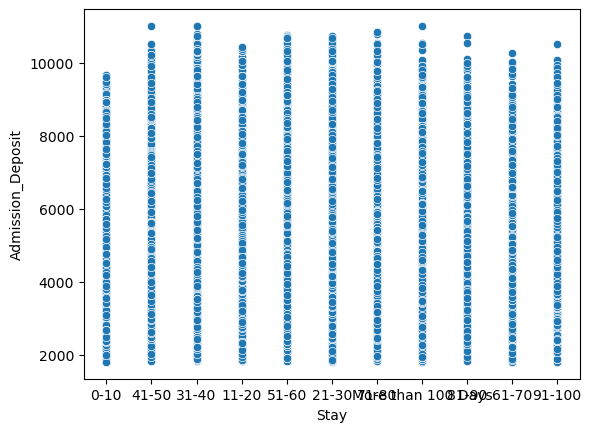

In [47]:
sns.scatterplot(
    x=data_train['Stay'],
    y=data_train["Admission_Deposit"]
)
plt.show()

In [19]:
data_train["Stay_group"] = data_train["Stay"].replace({
    "0-10": "Corta Estancia",
    "11-20": "Corta Estancia",
    "21-30": "Media Estancia",
    "31-40": "Media Estancia",
    "41-50": "Media Estancia",
    "51-60": "Larga Estancia",
    "61-70": "Larga Estancia",
    "71-80": "Larga Estancia",
    "81-90" : "Larga Estancia",
    "91-100" : "Larga Estancia",
    "More than 100 Days": "Larga Estancia",
})

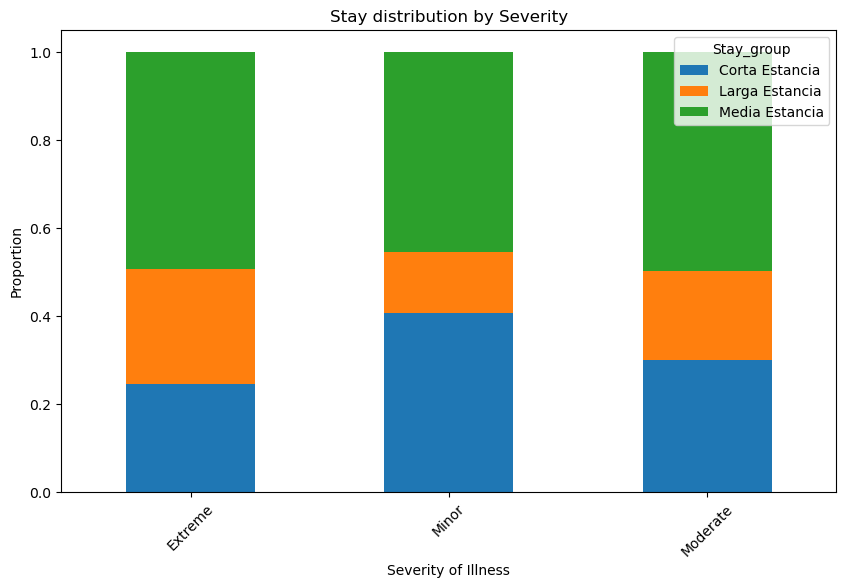

In [20]:
severity_stay = data_train.groupby(['Severity of Illness','Stay_group']).size().unstack()

severity_stay.div(severity_stay.sum(axis=1), axis=0).plot(kind='bar', stacked=True, figsize=(10,6))

plt.title("Stay distribution by Severity")
plt.ylabel("Proportion")
plt.xticks(rotation=45)
plt.show()

In [3]:
data_train['Department'].unique()

array(['radiotherapy', 'anesthesia', 'gynecology', 'TB & Chest disease',
       'surgery'], dtype=object)

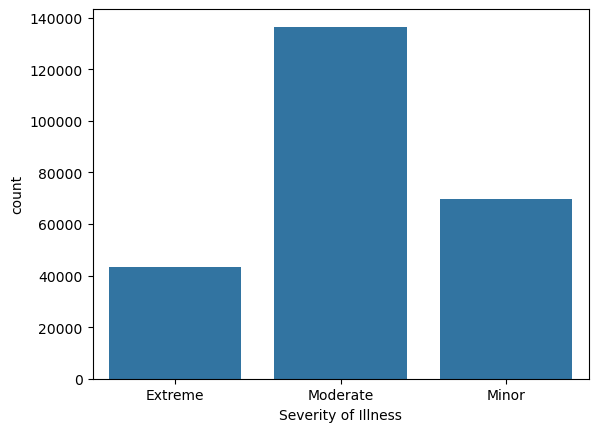

In [4]:
sns.countplot(
    data = data_train[data_train['Department'] == 'gynecology'],
    x = "Severity of Illness"
)
plt.show()

## COMPROBAR RELACIONES DE CODIGO DE HOSPITAL Y COGIDO TIPO DE HOSPITAL

In [11]:
pd.crosstab(
    data_train["Hospital_code"],
    data_train["Hospital_type_code"]
)

Hospital_type_code,a,b,c,d,e,f,g
Hospital_code,,,,,,,
1,0,0,0,5249,0,0,0
2,0,0,5102,0,0,0,0
3,0,0,7116,0,0,0,0
4,1240,0,0,0,0,0,0
5,5261,0,0,0,0,0,0
6,20425,0,0,0,0,0,0
7,1306,0,0,0,0,0,0
8,0,0,3663,0,0,0,0
9,0,0,0,11510,0,0,0


## COMPROBAR RELACIONES DE CODIGO DE HOSPITAL Y COGIDO CIUDAD DE HOSPITAL

In [10]:
pd.crosstab(
    data_train["Hospital_code"],
    data_train["City_Code_Hospital"]
)

City_Code_Hospital,1,2,3,4,5,6,7,9,10,11,13
Hospital_code,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,5249,0,0
2,0,0,0,0,5102,0,0,0,0,0,0
3,0,0,7116,0,0,0,0,0,0,0,0
4,0,0,0,1240,0,0,0,0,0,0,0
5,5261,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,20425,0,0,0,0,0
7,0,0,0,1306,0,0,0,0,0,0,0
8,0,0,3663,0,0,0,0,0,0,0,0
9,0,0,0,0,11510,0,0,0,0,0,0


In [ ]:
pd.crosstab(
    data_train["Hospital_code"],
    data_train["City_Code_Hospital"]
)

In [21]:
pd.crosstab(
    data_train['City_Code_Hospital'],
    data_train['Stay_group'],
    normalize='index'
)

Stay_group,Corta Estancia,Larga Estancia,Media Estancia
City_Code_Hospital,,,
1,0.335441,0.171776,0.492782
2,0.265649,0.198691,0.535660
3,0.305395,0.197821,0.496785
4,0.298189,0.230497,0.471314
5,0.316316,0.209098,0.474586
6,0.298270,0.188249,0.513481
7,0.450864,0.152864,0.396272
9,0.314686,0.245424,0.439890
10,0.272623,0.253572,0.473805


In [22]:
pd.crosstab(
    data_train['Hospital_type_code'],
    data_train['Stay_group'],
    normalize='index'
)

Stay_group,Corta Estancia,Larga Estancia,Media Estancia
Hospital_type_code,,,
a,0.351166,0.172132,0.476702
b,0.276709,0.203768,0.519523
c,0.302778,0.204712,0.492510
d,0.281377,0.228506,0.490117
e,0.341098,0.200767,0.458135
f,0.313464,0.294684,0.391853
g,0.199205,0.321955,0.478840


### Denominación de nulos teniendo en cuenta la información anterior

In [23]:
pd.crosstab(
    data_train['City_Code_Hospital'],
    data_train['City_Code_Patient'],
    normalize='index'
)

City_Code_Patient,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,29.0,30.0,31.0,32.0,33.0,34.0,35.0,36.0,37.0,38.0
City_Code_Hospital,,,,,,,,,,,,,,,,,,,,,
1,0.141636,0.128495,0.021465,0.040291,0.044960,0.013418,0.063103,0.322881,0.025839,0.083830,...,0.000314,0.000664,0.000314,0.000203,0.000277,0.000240,0.000037,0.000037,0.000258,0.000000
2,0.033784,0.118586,0.009868,0.043906,0.056528,0.015436,0.070577,0.484153,0.033550,0.010493,...,0.000508,0.000293,0.000449,0.000332,0.000371,0.000195,0.000117,0.000098,0.000117,0.000098
3,0.032116,0.058329,0.010652,0.087814,0.134401,0.073377,0.060158,0.298960,0.090317,0.009240,...,0.000289,0.000898,0.000096,0.000193,0.000193,0.000064,0.000032,0.000000,0.000417,0.000000
4,0.205449,0.208910,0.017747,0.029455,0.031149,0.005670,0.048748,0.272165,0.016937,0.052798,...,0.000295,0.000295,0.000000,0.000074,0.000074,0.000074,0.000000,0.000074,0.000147,0.000000
5,0.024428,0.039326,0.007904,0.144293,0.188466,0.040432,0.053801,0.257815,0.097290,0.004033,...,0.000163,0.000260,0.000293,0.000260,0.000033,0.000195,0.000033,0.000098,0.000065,0.000033
6,0.103337,0.312715,0.014080,0.018146,0.025326,0.004780,0.067976,0.307632,0.014728,0.030668,...,0.000216,0.000389,0.000000,0.000087,0.000151,0.000043,0.000000,0.000000,0.000130,0.000000
7,0.009475,0.020913,0.004979,0.010613,0.013089,0.002419,0.049310,0.840632,0.007569,0.001878,...,0.000398,0.000199,0.000057,0.000000,0.000427,0.000114,0.000028,0.000000,0.000057,0.000000
9,0.023587,0.050295,0.009365,0.057271,0.074614,0.017960,0.205766,0.364628,0.047790,0.004201,...,0.000385,0.000231,0.000193,0.000116,0.000270,0.000231,0.000116,0.000000,0.000308,0.000000
10,0.020239,0.045297,0.006939,0.031997,0.035659,0.005397,0.322475,0.432151,0.019275,0.004241,...,0.000193,0.000771,0.000000,0.000193,0.000771,0.000000,0.000000,0.000000,0.000000,0.000000


In [43]:
data_train['patientid'].value_counts().head()

patientid
66714     50
91292     43
38525     39
101359    36
33491     34
Name: count, dtype: int64

In [44]:
(data_train['patientid'].value_counts() > 1).sum()

np.int64(71668)

In [50]:
df_td_copy1 = data_train.copy()

In [51]:
df_td_copy1["Numero_registros_paciente"] = df_td_copy1["patientid"].map(df_td_copy1["patientid"].value_counts())

In [52]:
df_td_copy1

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Stay_group,Numero_registros_paciente
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911.0,0-10,Corta Estancia,14
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954.0,41-50,Media Estancia,14
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745.0,31-40,Media Estancia,14
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272.0,41-50,Media Estancia,14
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558.0,41-50,Media Estancia,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318433,318434,6,a,6,X,3,radiotherapy,Q,F,4.0,86499,23.0,Emergency,Moderate,3,41-50,4144.0,11-20,Corta Estancia,1
318434,318435,24,a,1,X,2,anesthesia,Q,E,4.0,325,8.0,Urgent,Moderate,4,81-90,6699.0,31-40,Media Estancia,1
318435,318436,7,a,4,X,3,gynecology,R,F,4.0,125235,10.0,Emergency,Minor,3,71-80,4235.0,11-20,Corta Estancia,1
318436,318437,11,b,2,Y,3,anesthesia,Q,D,3.0,91081,8.0,Trauma,Minor,5,11-20,3761.0,11-20,Corta Estancia,1


In [54]:
df_td_copy1[df_td_copy1['Numero_registros_paciente'] > 1]

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Stay_group,Numero_registros_paciente
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911.0,0-10,Corta Estancia,14
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954.0,41-50,Media Estancia,14
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745.0,31-40,Media Estancia,14
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272.0,41-50,Media Estancia,14
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558.0,41-50,Media Estancia,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318348,318349,25,e,1,X,2,gynecology,S,E,4.0,88623,7.0,Urgent,Minor,2,61-70,4616.0,11-20,Corta Estancia,2
318362,318363,12,a,9,Y,2,gynecology,S,B,2.0,2862,7.0,Emergency,Minor,2,0-10,3886.0,31-40,Media Estancia,2
318363,318364,22,g,9,Y,2,gynecology,S,B,2.0,2862,7.0,Emergency,Minor,2,0-10,4163.0,21-30,Media Estancia,2
318377,318378,12,a,9,Y,4,gynecology,Q,B,2.0,58605,9.0,Urgent,Moderate,2,21-30,4984.0,21-30,Media Estancia,2


In [55]:
df_td_copy1.loc[
    df_td_copy1['Numero_registros_paciente'] > 1,
    'patientid'
].unique()

array([31397, 63418,  8088, ..., 88623,  2862, 58605], shape=(71668,))

In [56]:
df_td_copy1[
    (df_td_copy1['Numero_registros_paciente'] > 1) &
    (df_td_copy1['City_Code_Patient'].isna())
]

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay,Stay_group,Numero_registros_paciente
191,192,14,a,1,X,2,radiotherapy,Q,E,3.0,122110,NaN,Emergency,Minor,2,71-80,9096.0,51-60,Larga Estancia,5
192,193,30,c,3,Z,2,anesthesia,Q,A,4.0,122110,NaN,Trauma,Minor,2,71-80,5098.0,31-40,Media Estancia,5
193,194,27,a,7,Y,2,radiotherapy,P,C,3.0,122110,NaN,Trauma,Minor,2,71-80,7776.0,21-30,Media Estancia,5
194,195,27,a,7,Y,2,anesthesia,Q,C,3.0,122110,NaN,Trauma,Minor,2,71-80,5988.0,11-20,Corta Estancia,5
195,196,25,e,1,X,3,radiotherapy,S,E,3.0,122110,NaN,Urgent,Minor,2,71-80,5333.0,21-30,Media Estancia,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317652,317653,32,f,9,Y,2,anesthesia,S,B,2.0,91539,NaN,Emergency,Moderate,4,31-40,3180.0,71-80,Larga Estancia,2
317761,317762,6,a,6,X,3,gynecology,R,F,1.0,121084,NaN,Emergency,Extreme,7,41-50,3129.0,31-40,Media Estancia,2
317762,317763,29,a,4,X,3,gynecology,S,F,2.0,121084,NaN,Emergency,Extreme,4,41-50,3091.0,31-40,Media Estancia,2
318023,318024,26,b,2,Y,3,gynecology,R,D,2.0,16158,NaN,Trauma,Minor,2,31-40,4917.0,21-30,Media Estancia,2


In [60]:
df_td_copy1.loc[
    df_td_copy1['City_Code_Patient'].isna(),
    'patientid'
].nunique()

1665

In [61]:
# Pacientes con algún nulo
patients_with_null = df_td_copy1.loc[
    df_td_copy1['City_Code_Patient'].isna(),
    'patientid'
].unique()

# Filtrar solo esos pacientes
subset = df_td_copy1[df_td_copy1['patientid'].isin(patients_with_null)]

# Ver si tienen valores no nulos en otra fila
recovery_check = subset.groupby('patientid')['City_Code_Patient'].agg(
    ['count', 'size']
)

recovery_check.head()

,count,size
patientid,,
549,0,2
554,0,4
711,0,2
844,0,5
1010,0,4


In [62]:
(recovery_check['count'] > 0).sum()

np.int64(0)

In [63]:
(recovery_check['count'] == 0).sum()

np.int64(1665)